In [1]:
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression

In [2]:
X, y = load_digits(return_X_y=True)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)
sc = StandardScaler().fit(Xtr); Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)

In [3]:
acc = lambda a, b: LogisticRegression(max_iter=2000).fit(a, ytr).score(b, yte)
print("Without PCA :", Xtr.shape[1], "features, accuracy =", round(acc(Xtr, Xte), 4))


Without PCA : 64 features, accuracy = 0.9778


In [4]:
pca = PCA(n_components=0.95).fit(Xtr)
print("With PCA    :", pca.n_components_, "features, accuracy =",
      round(acc(pca.transform(Xtr), pca.transform(Xte)), 4))


With PCA    : 40 features, accuracy = 0.96


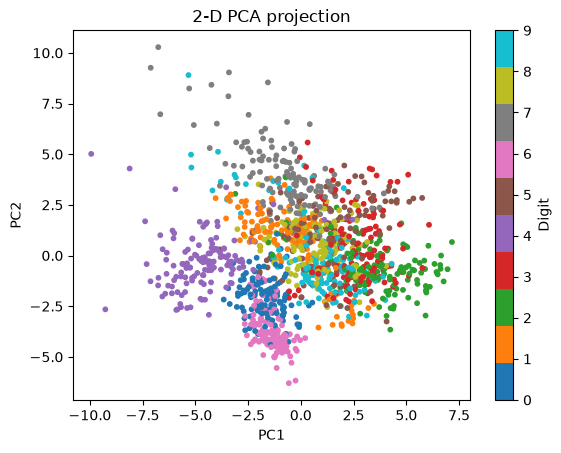

In [5]:
Z = PCA(n_components=2).fit_transform(Xtr)
plt.scatter(Z[:, 0], Z[:, 1], c=ytr, cmap="tab10", s=10)
plt.xlabel("PC1"); plt.ylabel("PC2"); plt.colorbar(label="Digit")
plt.title("2-D PCA projection"); plt.savefig("pr8_short_plot.png")